Julia Lacsan 101306494
Assignment three Psyc 3000 A


In [66]:
!mamba install pandas numpy matplotlib seaborn pingouin scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, pingouin, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.133 seconds
All requested packages already installed.


In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

nhanes = pd.read_csv(
    "https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv"
)

children = nhanes[
    nhanes["AgeInYearsAtScreening"] < 18
].copy()


/tmp/xpython_42/1406309654.py:7: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv(


## Question 1: SPSS Features vs. Pandas Equivalents

Aggregation (`Data > Aggregate`): 
  Accomplished using `.groupby()` along with summary functions like `.mean()`, `.median()`, or `.agg()`. It groups data by categorical variables to compute summary statistics across subsets.

Select Cases (`Data > Select If`):
  Accomplished using boolean indexing (e.g., `children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]`) or `.query()`. It filters DataFrame rows based on specific variable ranges or logical conditions.

Recode Values (`Transform > Recode`) 
  Accomplished using `.replace()`, `.map()`, or `.isin().astype(int)` (e.g., mapping `"Female"` to `1` or mapping survey sentinel numbers to missing values).

Missing Values (System / User-missing):
  Equivalent to `pd.NA` or `np.nan` in pandas, which are handled and excluded using functions like `.dropna()` or `.isna()`.

In [68]:
children.groupby("Gender")["StandingHeightCm"].agg(
    ["mean", "median", "std", "count"]
)

,mean,median,std,count
Gender,,,,
Female,133.996530,137.8,25.036093,1297
Male,137.868706,137.2,27.705938,1275


# 2A Line one 
(`(children["StandingHeightCm"] -children["StandingHeightCm"].mean()).hist()`): calculates the mean centered standing height by subtracting the mean height from each value. The distribution is centered at 0, with values representing deviations in centimeters (ranging from approximately -60 cm to +60 cm).

<Axes: >

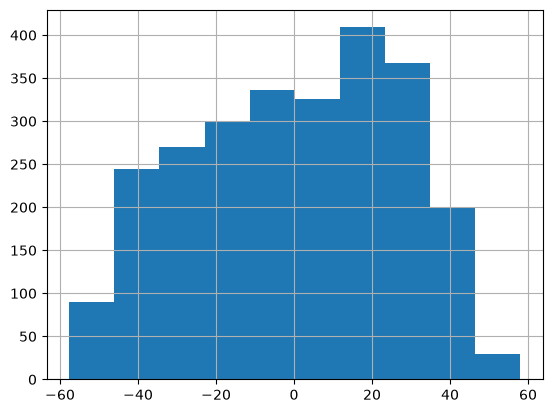

In [69]:
#2A
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()
#vs

# 2A Line 2 
(`((children["StandingHeightCm"] - children["StandingHeightCm"].mean()) / children["StandingHeightCm"].std()).hist()`):  Calculates standardized z-scores by dividing the mean-centered height by the standard deviation. The distribution is centered at 0, with values representing standard deviation units (ranging from approximately -2 to +2 SDs).

# 2A Comparison of the Two Code Lines: 
Both lines produce histograms with the exact same visual shape and frequency counts (y-axis). However, Line 1 scales the data in original measurement units (centimeters), whereas Line 2 standardizes the data into standard deviation units (z-scores).

<Axes: >

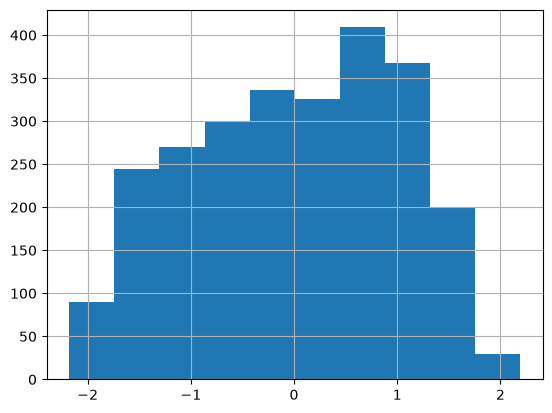

In [70]:
#2A
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

# 2B Line 1 
(`children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()`):Generates side-by-side histograms of standing height and age directly from the dataset. If raw survey data contains numeric missing-data codes (such as 7, 9, 77, 99, 777, 999, 7777, 9999), they will be treated as valid numeric values and plotted as extreme outlier bars on the histograms.

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

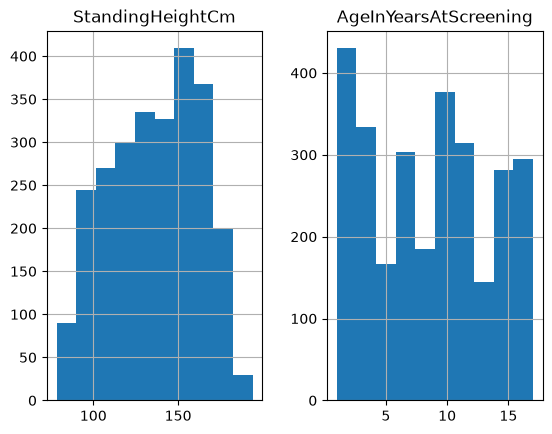

In [71]:
#2B
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()
#vs.

# 2B Line 2 
(`children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()`): First recodes all specified survey missing/refusal codes (e.g., 7, 9, 77, 99) to proper pandas missing values (`pd.NA`) and converts data types to nullable floats before plotting.

# 2B Comparison of the Two Code Lines:
Line 1 plots raw data without explicitly cleaning survey sentinel values, which risks plotting artificial data points if those codes are present. Line 2 explicitly cleans the data by replacing sentinel missing codes with `pd.NA` prior to plotting. Because the `children` subset was already filtered for `AgeInYearsAtScreening < 18` (which automatically excludes high codes like 77 or 999 for age), the resulting histograms appear identical, but Line 2 represents the robust data-cleaning best practice.

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

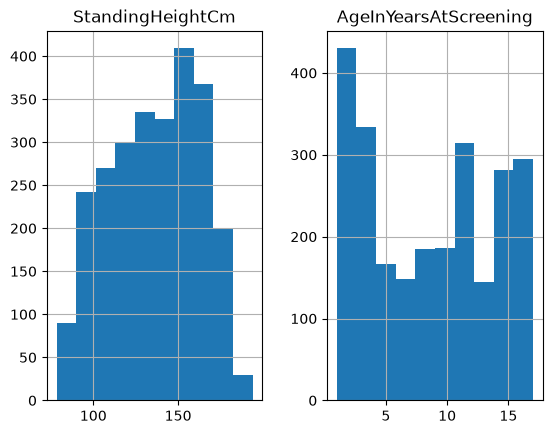

In [72]:
#2B
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

# 2C Line 1
(`children["AgeInYearsAtScreening"].describe()`): Computes summary statistics (count, mean, std, min, percentiles, max) for the age variable using pandas' standard `.describe()` method.

In [73]:
#2C
children["AgeInYearsAtScreening"].describe()
# vs.

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

# 2C Line 2 
(`children["AgeInYearsAtScreening"].dropna().describe()`): Explicitly drops any missing values (`NaN`/`pd.NA`) from the age variable using `.dropna()` before calculating summary statistics.

# 2C Comparison of the Two Code Lines:
Both lines produce identical summary statistics (count = 2833, mean = 8.51, std = 4.91). This is because pandas' statistical methods—including `.describe()`—automatically and implicitly ignore missing values by default (`skipna=True`). Therefore, explicitly calling `.dropna()` beforehand produces the exact same numerical result.

In [74]:
#2C
children["AgeInYearsAtScreening"].dropna().describe()


count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [75]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


# 2D With line 2 
(`sns.regplot(data=nhanes, x="StandingHeightCm", y="BodyMassIndexKgm2", scatter_kws={"color": "C0", "alpha": 0.3}, line_kws={"color": "red"})`): Generates a visual scatter plot with an overlaid red linear regression trendline and confidence interval band.

<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

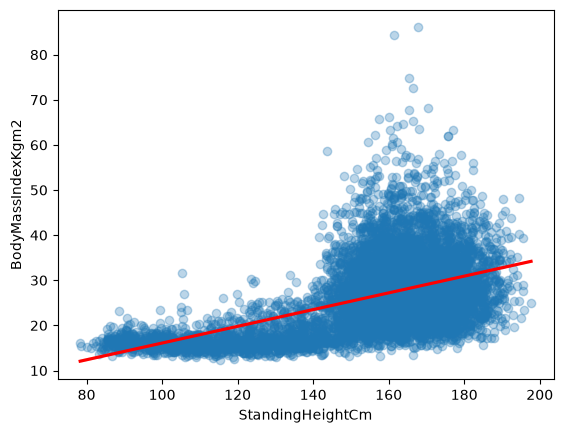

In [76]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

# 2D Comparison of running WITH vs. WITHOUT Line 2:
WITHOUT Line 2 (only `pg.linear_regression`): Python outputs only the numerical statistical summary table containing coefficients, ,p-values, without generating any visual plot.
WITH Line 2 added (`sns.regplot`):Python creates and renders the visual scatter plot with the red regression trendline. 
Conclusion: Line 1 produces the statistical numbers/table, whereas Line 2 produces the data visualization/graph.


In [77]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


## Question 3: Description and Comparison of Figure 5.3 Panels

Figure 5.3 illustrates the height of children in NHANES across four distinct panels (A, B, C, and D), showing how regression models evolve as predictors and constraints change:

Panel A (original data): 
  Displays the raw scatter plot of children's standing height against age without any fitted model line. It shows a positive non-linear trend where height increases rapidly with age before leveling off around ages 15–18.

Panel B (age / no constant):
  Corresponds to model `m_age = LinearRegression(fit_intercept=False)`. It fits a simple linear regression using only age, but forces the intercept through the origin $(0, 0)$. Because an age of 0 is forced to equal 0 cm height, the fitted line drastically underestimates height for younger children (ages 2–8) and overestimates height for older children.

Panel C (age + constant):
  Corresponds to model `m_age_const = LinearRegression()`. It includes an estimated intercept (constant term), allowing the regression line to shift upwards to better fit the data across all ages rather than forcing it through $(0, 0)$.

Panel D (age + constant + gender / interaction model):
  Corresponds to `m_full` / `m_interaction`. It incorporates gender as a factor alongside age, fitting separate regression lines for females (pink) and males (cyan). This panel allows both the intercept and slope to differ by gender, demonstrating that males and females have slightly different growth trajectories over time.

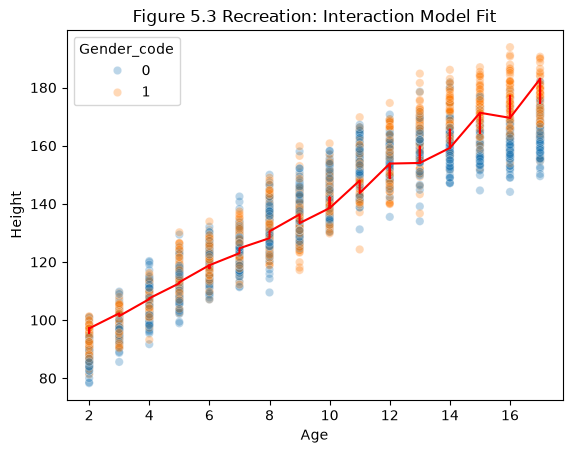

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Recode gender and filter non-null children data
children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children_clean = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna().copy()

# Fit models
m_age = LinearRegression(fit_intercept=False).fit(children_clean[["AgeInYearsAtScreening"]], children_clean["StandingHeightCm"])
m_age_const = LinearRegression().fit(children_clean[["AgeInYearsAtScreening"]], children_clean["StandingHeightCm"])
m_full = LinearRegression().fit(children_clean[["AgeInYearsAtScreening", "Gender_code"]], children_clean["StandingHeightCm"])

children_clean = children_clean.sort_values("AgeInYearsAtScreening")
children_clean["pred_age"] = m_age.predict(children_clean[["AgeInYearsAtScreening"]])
children_clean["pred_age_const"] = m_age_const.predict(children_clean[["AgeInYearsAtScreening"]])
children_clean["pred_full"] = m_full.predict(children_clean[["AgeInYearsAtScreening", "Gender_code"]])

# Interaction term & model
children_clean["Age_Gender"] = (children_clean["AgeInYearsAtScreening"] * children_clean["Gender_code"])
m_interaction = LinearRegression().fit(children_clean[["AgeInYearsAtScreening", "Gender_code", "Age_Gender"]], children_clean["StandingHeightCm"])
children_clean["pred_interaction"] = m_interaction.predict(children_clean[["AgeInYearsAtScreening", "Gender_code", "Age_Gender"]])

# Display fitted sample graph
sns.scatterplot(data=children_clean, x="AgeInYearsAtScreening", y="StandingHeightCm", hue="Gender_code", alpha=0.3)
plt.plot(children_clean["AgeInYearsAtScreening"], children_clean["pred_interaction"], color="red", label="Interaction Fit")
plt.title("Figure 5.3 Recreation: Interaction Model Fit")
plt.xlabel("Age")
plt.ylabel("Height")
plt.show()